> **This notebook needs an Arraylake account.** It reads the Arraylake repository
> `earthmover-demos/xenium-lung-virtual`, and Arraylake has no anonymous read. The committed run
> loaded seven elements from that repository and plotted them. It concatenated 12 referenced
> transcript tiles into 190,077 transcripts. The outputs below ship executed. A reader without
> an account sees every figure this run produced.

# Technology focus: Xenium

This notebook will present an overview of the plotting functionalities of the `spatialdata` framework, in the context of a Xenium dataset.

Other notebooks, focused on data manipualtion, are also available for Xenium data:
- Alignment of a Xenium and Visium datasets (this is one of the reproducibility notebooks for the analysis of our paper) [notebook](https://github.com/scverse/spatialdata-notebooks/blob/main/notebooks/paper_reproducibility/00_xenium_and_visium.ipynb)
- Workflow showing saving annotations in Xenium Explorer and accessing them in SpaitalData, and viceversa [notebook](https://github.com/quentinblampey/spatialdata_xenium_explorer/blob/master/docs/10x_tutorials/xenium/xenium_tuto.ipynb). Tutorial from Quentin Blampey.

## What differs from the scverse notebook

This notebook replaces [the scverse notebook of the same name](https://spatialdata.scverse.org/en/stable/tutorials/notebooks/notebooks/examples/technology_xenium.html). It keeps their text
and their calls. It runs them against an Arraylake repository that **holds almost none of the
data**. The images, the segmentation masks, the transcripts and the counts are byte ranges into the
files that 10x published. We did not download or convert any file.

The full list of differences:

- **Loading.** `sd.read_zarr(session.store)` replaces `sd.read_zarr(path)`. The call runs inside
  `isd.parquet_in_store()`, which lets the shapes read from the store. The loading cell has no other
  change. The TIFF parser that wrote the image references also supplies their JPEG 2000 codec.
- **Reads.** `isd.repository_config()` retries a dropped connection. `isd.bounded_reads()` limits
  the number of connections that one compute opens. Neither function changes a result.
- **`morphology_focus` has one channel, not four.** 10x publish the other three only inside their
  8 GB `outs.zip`, and they deflate them there. A deflated zip member is one Huffman-coded stream.
  Thus no offset *inside* it is addressable, and no reference can point to a tile of those images.
  The stored members of the same archive are different: the segmentation masks come from them. The
  deflate saves under 0.01%, because an OME-TIFF already holds compressed data; see
  [`../icechunk-SpatialData/upstream/`](../icechunk-SpatialData/upstream). The channel present is
  DAPI. That is what this element actually is.
- **The transcripts come from referenced tiles.** The notebook assembles them and does not read a
  parquet. 10x published `transcripts.parquet` with a whole-object checksum. S3 returns that
  checksum on ranged responses too. Thus a client could not validate any byte range into the file.
  That header has since moved to `transcripts.zarr.zip`, the archive that these tiles come from.
  The header broke this cell until we repointed the references from 10x's CDN to their origin
  bucket. The origin bucket does not send the header at all.
  [`../icechunk-SpatialData/upstream/`](../icechunk-SpatialData/upstream) describes both problems.
  The archive stores transcripts as a pyramid of tiles. A virtual Zarr array cannot span two source
  arrays. Thus the notebook concatenates the tiles on read. That concatenation is the blocker that
  remains.
- **This notebook omits `%load_ext jupyter_black`**, because this environment does not have it.

Everything else is theirs, including the crop coordinates. Two other facts are useful, but they are
*not* differences. First, `he_image` is interleaved RGB. 10x store it as `(y, x, c)`, and an
element must be `(c, y, x)`. It is a real element nonetheless. Zarr's `transpose` codec permutes
the axes on read, so 10x's bytes stay unchanged. Second, the cell and nucleus masks come from a
published `.zarr.zip`. A zip's central directory locates every member. 10x wrote their members
uncompressed, so each Zarr chunk is a contiguous range. The blosc codec that decodes the chunks is
already part of Zarr v3.

In [1]:
%load_ext autoreload
%autoreload 2

## Loading the data

A reader for Xenium data is available in `spatialdata-io`. The scverse notebook uses it to parse and
convert to Zarr a [Xenium dataset of Human Lung
Cancer](https://www.10xgenomics.com/datasets/preview-data-ffpe-human-lung-cancer-with-xenium-multimodal-cell-segmentation-1-standard).

Information regarding data licensing and attribution for the dataset listed above is also available
at: https://github.com/scverse/spatialdata-notebooks/tree/main/datasets.

Here the notebook reads the same dataset, and it does not download or convert it.
`earthmover-demos/xenium-lung-virtual` references 10x's published files directly. It follows the
conventions of `spatialdata_io`: the same element names, and pixel space. The rasters have an
identity transformation. The vector data has a scale from microns to pixels.

The dataset used in this notebook is the latest Xenium Multimodal Cell Segmentation extension of the
Xenium technology, available for data processed using Xenium Analyzer version 2.0.0 and when Cell
Segmentation Kit was used.

In [2]:
repo_name = "earthmover-demos/xenium-lung-virtual"

In [3]:
%%time
import warnings

warnings.simplefilter("ignore")

import spatialdata as sd  # noqa: F401
import spatialdata_plot  # noqa: F401
from arraylake import Client
from arraylake import config as al_config

import icechunk_spatialdata as isd

# The published repo is on prod. A local config can point the client at dev.
al_config.set({"service.uri": "https://api.earthmover.io"})

session = Client().get_repo(repo_name, config=isd.repository_config()).readonly_session("main")
isd.bounded_reads()
with isd.parquet_in_store():
    sdata = sd.read_zarr(session.store)

for kind in ("images", "labels", "shapes", "tables"):
    for name in getattr(sdata, kind):
        print(f"{kind}/{name}")

images/he_image
images/morphology_focus
labels/cell_labels
labels/nucleus_labels
shapes/cell_circles
shapes/cell_boundaries
tables/table
CPU times: user 3.89 s, sys: 1.1 s, total: 4.99 s
Wall time: 57.6 s


The datasets contains 2 large microscopy image, represented as a multiscale, chunked image; the first one, `he_image` is the H&E image of the tissue, stained post-Xenium measurement, and the `morphology_focus` image which consists of the image of the tissue used for the Xenium experiment.

Furthermore, it also contains label images, that are the segmentation masks of cells or nuclei (`cell_labels` and `nucleus_labels` respectively).

## Plotting the images

Let's visualize the images.

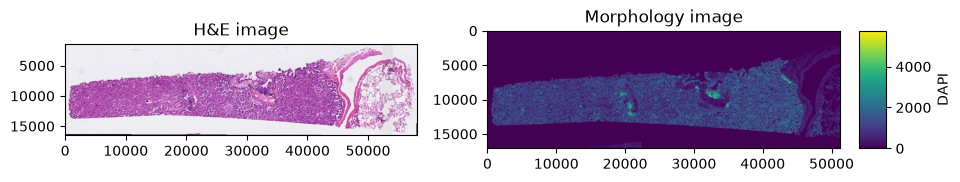

In [4]:
import matplotlib.pyplot as plt

axes = plt.subplots(1, 2, figsize=(10, 10))[1].flatten()
sdata.pl.render_images("he_image").pl.show(ax=axes[0], title="H&E image")
sdata.pl.render_images("morphology_focus").pl.show(ax=axes[1], title="Morphology image")

We can also crop and visualize a smaller region to appreciate morphological differences measured by the two modalities, together with the cell segmentation mask. Spatial cropping is introduced in a dedicated notebook in the documentation.

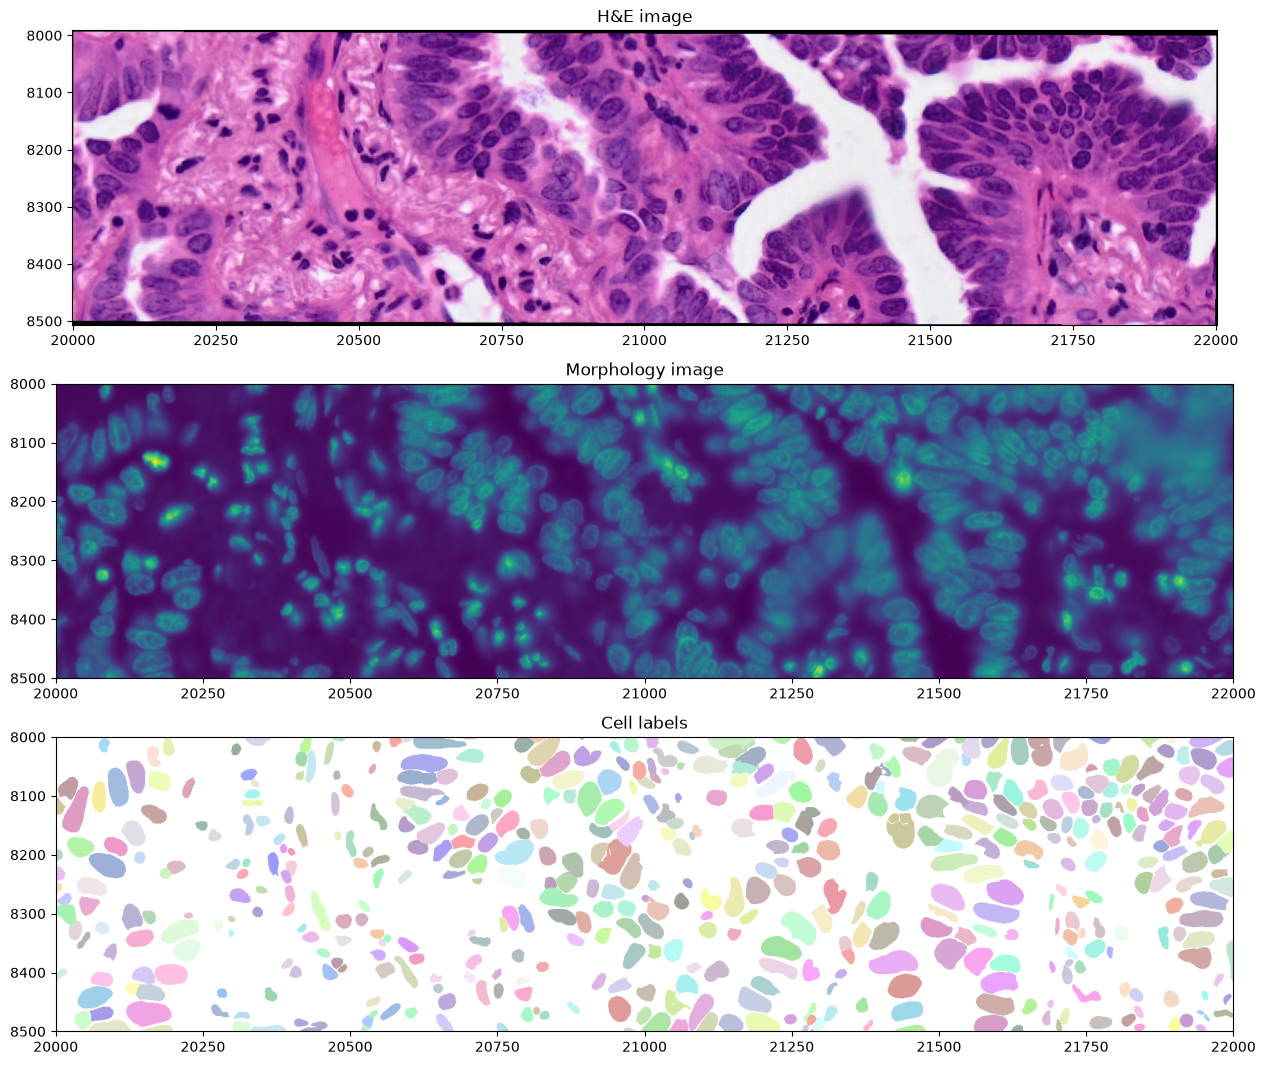

In [5]:
from spatialdata import bounding_box_query

axes = plt.subplots(3, 1, figsize=(20, 13))[1].flatten()


def crop0(x):
    return bounding_box_query(
        x,
        min_coordinate=[20_000, 8000],
        max_coordinate=[22_000, 8500],
        axes=("x", "y"),
        target_coordinate_system="global",
    )


crop0(sdata).pl.render_images("he_image").pl.show(
    ax=axes[0], title="H&E image", coordinate_systems="global"
)
crop0(sdata).pl.render_images("morphology_focus", channel="DAPI").pl.show(
    ax=axes[1], title="Morphology image", coordinate_systems="global", colorbar=False
)
crop0(sdata).pl.render_labels("cell_labels").pl.show(
    ax=axes[2], title="Cell labels", coordinate_systems="global"
)

## Exploring the multimodal segmentation

Let's visualize the 4 channels that are used, for this dataset, for computing the cell segmentation.
This is specific for datasets profiled using the Cell Segmentation Kit and processed with the Xenium
Analyzer >= 2.0.0.

Only DAPI is available here. The first section gives the reason.

In [6]:
from spatialdata.models import get_channel_names

channel_names = get_channel_names(sdata["morphology_focus"])
channel_names

['DAPI']

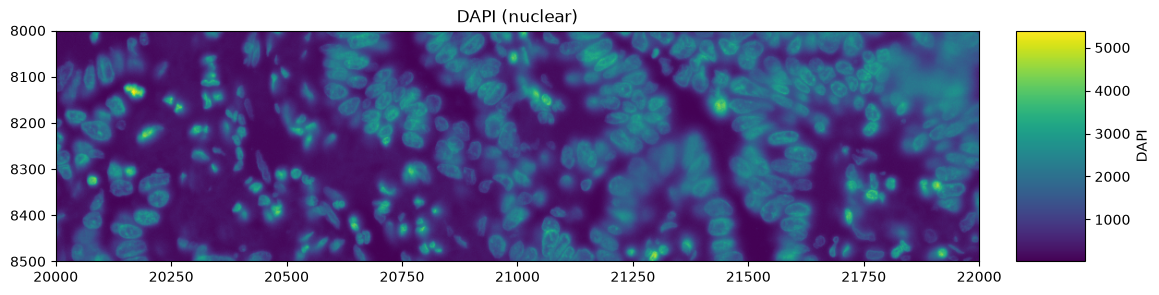

In [7]:
crop0(sdata).pl.render_images("morphology_focus", channel=channel_names[0]).pl.show(
    title="DAPI (nuclear)", figsize=(10, 3)
)

## Plotting the gene expression data

With SpatialData we can also plot gene expression data on top of the images. We can plot the expression of a single gene, or the expression of multiple genes.
To showcase different functionalities, we will use the `cell_circles` Shapes element to overlay gene expression over the image, instead of the raster labels showed above.

Let's first normalize and select highly variable genes.

In [8]:
import scanpy as sc

sc.pp.normalize_total(sdata.tables["table"])
sc.pp.log1p(sdata.tables["table"])
sc.pp.highly_variable_genes(sdata.tables["table"])
sdata.tables["table"].var.sort_values("means")

,gene_id,feature_type,highly_variable,means,dispersions,dispersions_norm
gene,,,,,,
UnassignedCodeword_0444,UnassignedCodeword_0444,Unassigned Codeword,False,1.000000e-12,NaN,NaN
UnassignedCodeword_0465,UnassignedCodeword_0465,Unassigned Codeword,False,1.000000e-12,NaN,NaN
UnassignedCodeword_0485,UnassignedCodeword_0485,Unassigned Codeword,False,1.000000e-12,NaN,NaN
UnassignedCodeword_0402,UnassignedCodeword_0402,Unassigned Codeword,False,1.000000e-12,NaN,NaN
UnassignedCodeword_0403,UnassignedCodeword_0403,Unassigned Codeword,False,1.000000e-12,NaN,NaN
...,...,...,...,...,...,...
CAPN8,ENSG00000203697,Gene Expression,True,8.594281e-01,1.032666,1.000000
EPCAM,ENSG00000119888,Gene Expression,False,8.977255e-01,0.938616,-0.707107
TCIM,ENSG00000176907,Gene Expression,True,9.482847e-01,1.136128,0.707107


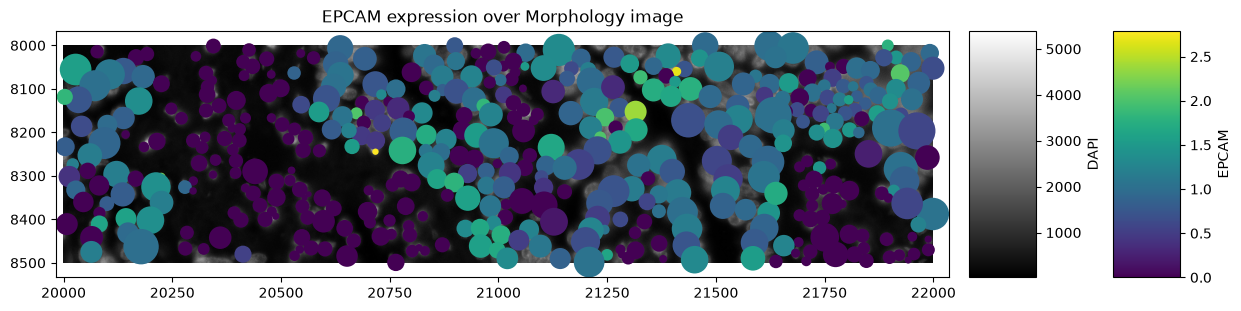

In [9]:
gene_name = "EPCAM"
crop0(sdata).pl.render_images("morphology_focus", channel="DAPI", cmap="gray").pl.render_shapes(
    "cell_circles",
    color=gene_name,
).pl.show(
    title=f"{gene_name} expression over Morphology image",
    coordinate_systems="global",
    figsize=(10, 3),
)

We can also assign the table to a different region, in order to overlay the gene expression for the specified region.
SpatialData stores the information of which region is the table in the following places:
- in `sdata.tables[<table_name>].uns["spatialdata_attrs]["region"]` it stores the regions that the table is annotating.
- The name of the region is stored under `sdata.tables[<table_name>].obs["region_key"]`.

We can use a utility function to modify that information, and hence plot the gene expression for a different shapes.

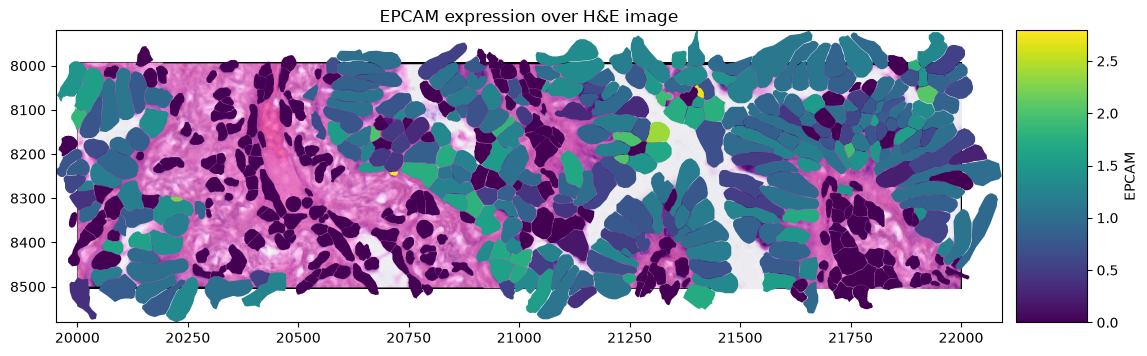

In [10]:
sdata.tables["table"].obs["region"] = "cell_boundaries"
sdata.set_table_annotates_spatialelement("table", region="cell_boundaries")

crop0(sdata).pl.render_images("he_image").pl.render_shapes(
    "cell_boundaries",
    color=gene_name,
).pl.show(
    title=f"{gene_name} expression over H&E image",
    coordinate_systems="global",
    figsize=(10, 5),
)

Finally, we can also plot transcript locations, together with the same layers selected as before.

In [11]:
import numpy as np
import pandas as pd
import zarr
from spatialdata.models import PointsModel
from spatialdata.transformations import Scale

store = zarr.open_group(session.store, mode="r")
# Read `pixel_size` from the run record, not from a constant. The store holds the
# experiment.xenium file that 10x published beside the bundle.
PIXEL_SIZE = dict(store.attrs)["experiment_xenium"]["contents"]["pixel_size"]
grid = store["points_virtual"]["transcripts"]
gene_names = list(grid.attrs["gene_names"])

frames = []
for tile in sorted(grid.group_keys()):
    location = np.asarray(grid[tile]["location"][:])            # microns
    identity = np.asarray(grid[tile]["gene_identity"][:]).ravel()
    frames.append(pd.DataFrame({
        "x": location[:, 0], "y": location[:, 1],
        "feature_name": pd.Categorical([gene_names[i] for i in identity]),
    }))
transcripts = pd.concat(frames, ignore_index=True)

sdata.points["transcripts"] = PointsModel.parse(
    transcripts, feature_key="feature_name",
    transformations={"global": Scale([1 / PIXEL_SIZE, 1 / PIXEL_SIZE], axes=("x", "y"))},
)
print(f"{len(frames)} tiles concatenated -> {len(transcripts):,} transcripts")

12 tiles concatenated -> 190,077 transcripts


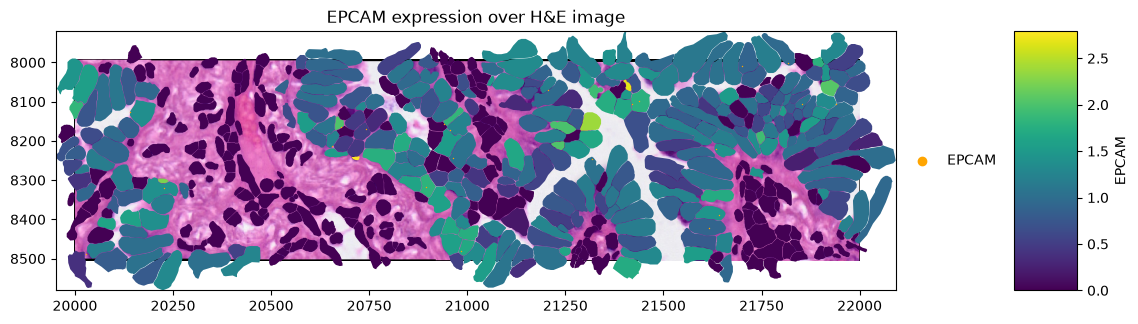

In [12]:
crop0(sdata).pl.render_images("he_image").pl.render_shapes(
    "cell_boundaries",
    color=gene_name,
).pl.render_points(
    "transcripts",
    color="feature_name",
    groups=gene_name,
    palette="orange",
).pl.show(
    title=f"{gene_name} expression over H&E image",
    coordinate_systems="global",
    figsize=(10, 5),
)